In [1]:
%run BaseFiles/Imports.ipynb
%run BaseFiles/Functions.ipynb

colour1 = "royalblue"
colour2 = "red"


/home/rahyndman/miniforge3/envs/sunpyVenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-15 16:27:34 - spiceypy.utils.libspicehelper - INFO: Using fallback library next to module: /net/maedoc.ap.dias.ie/maedoc/home_cr/rahyndman/miniforge3/envs/sunpyVenv/lib/python3.14/site-packages/spiceypy/utils/libcspice.so


In [2]:
# Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"

# Variables
DataSource = "Wind"
# Start  = "1995-01-01 00:00" # from T&C
Start  = "1996-01-01 00:00" # from SIDC
# End  = "2026-12-31 23:59"  # Up to most recent data (For Wind, not ICMECAT)
End = "1996-02-01 00:00"  # End of ICMECAT, after this we won't be able to remove the CMEs so stop the plotting here, EndOfCMECat

#Separated by data source as files may have different file name conventions
if DataSource == "Wind":
    YearlyRange = Yearly(Start, End, frequency = 'MS') # changed to monthly
    print(YearlyRange)
    dataTimeSerieses = []
    StartAndEnd = []
    for i in range(len(YearlyRange)-1):
        StartDate = YearlyRange[i]
        EndDate = YearlyRange[i][0:6] + "31"
        # print(StartDate, EndDate)
        # DateRange = ReadDates(StartDate, EndDate) # get date range
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        dataTS = dfToSeries(dataFound)
        dataTS = AddTotVsw(dataTS) # add totvsw
        # dataTS = AddBMag(dataTS) # add bmag
        # dataTS = AddLogBMag(dataTS) 
        # dataTS = AddLogBX(dataTS)
        dataTimeSerieses.append(dataTS)
        StartAndEnd.append([StartDate, EndDate])

else:
    print("Data source not known")

['19960101', '19960201']


In [3]:
print(dataTimeSerieses)

SunPy TimeSeries
----------------
Observatory:			Unknown
Instrument:			Unknown
Channel(s):			Year<br>DOY<br>Hour<br>Minute<br>IMF_PTS<br>PercentInterp<br>CP/MVFlag<br>Timeshift<br>PFN_XGSE<br>PFN_YGSE<br>PFN_ZGSE<br>ScalarB<br>Bx_GSEGSM<br>ByGSE<br>BzGSE<br>ByGSM<br>BzGSM<br>RMSTimeshift<br>RMS_PFN<br>RMSScalarB<br>RMSFieldVector<br>Plasma_PTS<br>FlowSpeed<br>Vx_GSE<br>Vy_GSE<br>Vz_GSE<br>ProtonDensity<br>Temp<br>X_s_c_GSE<br>Y_s_c_GSE<br>Z_s_c_GSE<br>X_targ_GSE<br>Y_targ_GSE<br>Z_targ_GSE<br>RMS_targ<br>DBOT1<br>DBOT2<br>TotVsw
Start Date:			1996-01-01 00:00:00
End Date:			1996-01-31 23:59:00
Center Date:			1996-01-16 11:59:30
Resolution:			59.999 s
Samples per Channel:		44640
Data Range(s):		Year             0.00E+00<br>DOY              3.00E+01<br>Hour             2.30E+01<br>Minute           5.90E+01<br>IMF_PTS          7.80E+01<br>PercentInterp    1.00E+02<br>CP/MVFlag        1.00E+00<br>Timeshift        6.36E+03<br>PFN_XGSE         8.90E-01<br>PFN_YGSE         1.92E+00<br>PFN_ZGS

File not saved
DateTime
1996-01-01 00:00:00    False
1996-01-01 00:01:00    False
1996-01-01 00:02:00    False
1996-01-01 00:03:00    False
1996-01-01 00:04:00    False
                       ...  
1996-01-31 23:55:00    False
1996-01-31 23:56:00    False
1996-01-31 23:57:00    False
1996-01-31 23:58:00    False
1996-01-31 23:59:00    False
Name: TotVsw, Length: 44640, dtype: bool
Caption: Time series of solar wind speed with highlighted times that the values stay within the first (395-405km/s, royalblue)
 and second (415-425km/s, red) threshold. Highlighted sections are coloured coded to show each threshold.


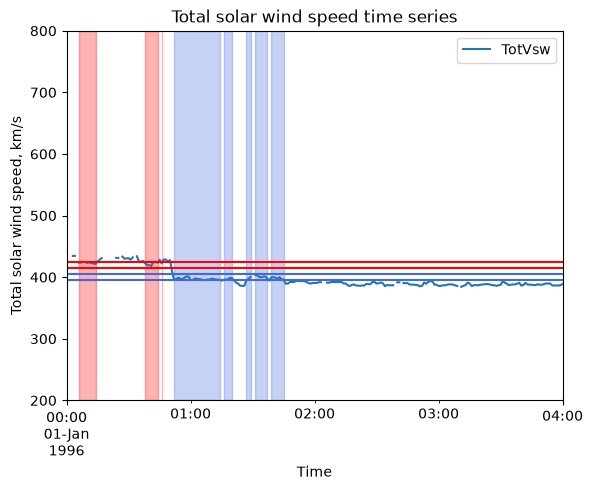

In [4]:
timestart = "1996-01-01 00:00"
timeend = "1996-01-01 04:00"
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [200,800])

Alpha = 0.3

# FirstBaseValue = 400
# SecondBaseValue = 600
# AbsoluteThreshold = 50

# plt.hlines(FirstBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color="green")
# plt.hlines(FirstBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color="green")
# plt.hlines(SecondBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color="red")
# plt.hlines(SecondBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color="red")

# print(dataTimeSerieses[0].to_dataframe()["TotVsw"])

# mask = dataTimeSerieses[0].to_dataframe()["TotVsw"].between(FirstBaseValue-AbsoluteThreshold, FirstBaseValue+AbsoluteThreshold)
# print(mask)

# # y = -1
# starts = []
# ends = []
# for x in range(len(mask)):
#     # y = y + 1
#     if mask.values[x] == True and mask.values[x-1] == False:
#         # print("Start")
#         starts.append(mask.index[x])
#     if mask.values[x] == True and mask.values[x-1] == True:
#         # print("Middle")
#         minor=0
#     if mask.values[x] == True and mask.values[x+1] == False:
#         # print("End")
#         ends.append(mask.index[x])
#     elif mask.values[x] == False:
#         minor=0
#         # print("Not in threshold")

# print(starts)
# print(ends)
# print(len(starts))
# print(len(ends))

#Multicoloured
# colors = ["red", "orange", "yellow", "green", "blue", "purple"]
# Colours = colors*(round(len(starts)/6))
# for y in range(len(starts)):
#     # print(y)
#     plt.axvspan(starts[y], ends[y], color = Colours[y], alpha = 0.1)

#Threshold 1
FirstBaseValue = 400
AbsoluteThreshold = 5

plt.hlines(FirstBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)
plt.hlines(FirstBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)

maskFirst = dataTimeSerieses[0].to_dataframe()["TotVsw"].between(FirstBaseValue-AbsoluteThreshold, FirstBaseValue+AbsoluteThreshold)

# y = -1
starts = []
ends = []
# nanCounter = 0
# notNanCounter = 0
for x in range(len(maskFirst)):
    # y = y + 1
    if maskFirst.values[x] == True and maskFirst.values[x-1] == False:
        # print("Start")
        starts.append(maskFirst.index[x])
    if maskFirst.values[x] == True and maskFirst.values[x-1] == True:
        # print("Middle")
        minor=0
    if maskFirst.values[x] == True and maskFirst.values[x+1] == False:
        # print("End")
        ends.append(maskFirst.index[x])
    elif maskFirst.values[x] == False:
        minor=0
        # print("Not in threshold")

for y in range(len(starts)):
    # print(y)
    # plt.axvspan(starts[y], ends[y], ymin = FirstBaseValue-AbsoluteThreshold, ymax = FirstBaseValue+AbsoluteThreshold, color = "green", alpha = 0.1)
    plt.axvspan(starts[y], ends[y], color = colour1, alpha = Alpha)



#Threshold 2
SecondBaseValue = 420
AbsoluteThreshold = 5

plt.hlines(SecondBaseValue + AbsoluteThreshold, xmin = timestart, xmax = timeend, color= colour2)
plt.hlines(SecondBaseValue - AbsoluteThreshold, xmin = timestart, xmax = timeend, color= colour2)

maskSecond = dataTimeSerieses[0].to_dataframe()["TotVsw"].between(SecondBaseValue-AbsoluteThreshold, SecondBaseValue+AbsoluteThreshold)
print(maskSecond)

# y = -1
startsSecond = []
endsSecond = []
for x in range(len(maskSecond)):
    # y = y + 1
    if maskSecond.values[x] == True and maskSecond.values[x-1] == False:
        # print("Start")
        startsSecond.append(maskSecond.index[x])
    if maskSecond.values[x] == True and maskSecond.values[x-1] == True:
        # print("Middle")
        minor=0
    if maskSecond.values[x] == True and maskSecond.values[x+1] == False:
        # print("End")
        endsSecond.append(maskSecond.index[x])
    elif maskSecond.values[x] == False:
        minor=0
        # print("Not in threshold")

for y in range(len(startsSecond)):
    # print(y)
    # plt.axvspan(startsSecond[y], endsSecond[y], ymin = SecondBaseValue-AbsoluteThreshold, ymax = SecondBaseValue+AbsoluteThreshold, color = "red", alpha = 0.1)
    plt.axvspan(startsSecond[y], endsSecond[y], color = colour2, alpha = Alpha)


#General plot settings
plt.title("Total solar wind speed time series")
plt.xlabel("Time")
plt.ylabel("Total solar wind speed, km/s")
print("Caption: Time series of solar wind speed with highlighted times that the values stay within the first ("+ str(FirstBaseValue-AbsoluteThreshold) + "-" + str(FirstBaseValue+AbsoluteThreshold)+"km/s, "+ colour1+")\n and second ("+ str(SecondBaseValue-AbsoluteThreshold) + "-" + str(SecondBaseValue+AbsoluteThreshold)+"km/s, "+ colour2+") threshold. Highlighted sections are coloured coded to show each threshold.")

# for x in range(len(mask)):
#     if mask[x]


# InThreshold = dataTimeSerieses[0].to_dataframe()[mask]
# print(InThreshold)
# TimeSeries(InThreshold).plot(columns="TotVsw")
# PlotVsw(TimeSeries(InThreshold), Columns=["TotVsw"], XLim =["1996-01-01 00:00", "1996-01-08 00:00"], YLim = [200,800])
# dfOnlyCMEs = dataTimeSerieses[i].to_dataframe()[~MapForINDEX]

# for x in dataTimeSerieses[0].to_dataframe()["TotVsw"]:
#     if x > FirstBaseValue-AbsoluteThreshold and x < FirstBaseValue+AbsoluteThreshold:
#         if x-1 < FirstBaseValue-AbsoluteThreshold or x-1 > FirstBaseValue+AbsoluteThreshold:
#             print("dataTimeSerieses[0][" + str(x) + "] start of range")
#             plt.vlines(x, ymin = 200, ymax = 800, color="green")
#         if x+1 < FirstBaseValue-AbsoluteThreshold or x+1 > FirstBaseValue+AbsoluteThreshold:
#             print("dataTimeSerieses[0][" + str(x) + "] end of range")
#         else:
#             print("not at start or end")

Caption: Histogram of steadiness timeframes for TotVsw for the first (395-405km/s, royalblue) and second (415-425km/s, red) threshold.


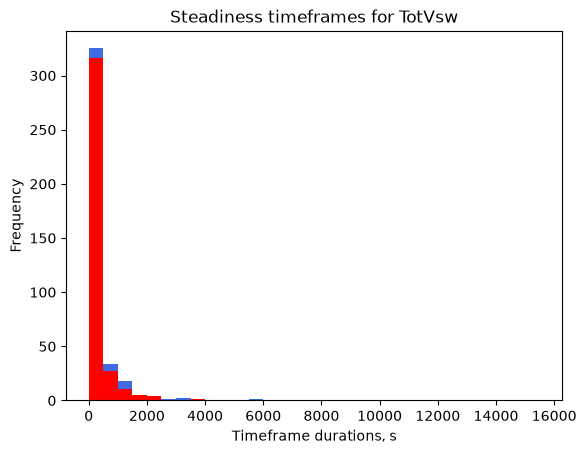

In [5]:
Bins = np.arange(0, 16000, 500)

#Threshold 1
tau1 = []
for x in range(len(starts)):
    tau1.append(ends[x]-starts[x])
# print(tau1)
tau1InSeconds = []
for y in range(len(tau1)):
    tau1InSeconds.append(tau1[y].total_seconds())
plt.hist(tau1InSeconds, bins = Bins, color= colour1)

#Threshold 2
tau2 = []
for x in range(len(startsSecond)):
    tau2.append(endsSecond[x]-startsSecond[x])
# print(tau2)
tau2InSeconds = []
for y in range(len(tau2)):
    tau2InSeconds.append(tau2[y].total_seconds())
plt.hist(tau2InSeconds, bins = Bins, color = colour2)

#General plot settings
plt.title("Steadiness timeframes for TotVsw")
plt.xlabel("Timeframe durations, s")
plt.ylabel("Frequency")
print("Caption: Histogram of steadiness timeframes for TotVsw for the first ("+ str(FirstBaseValue-AbsoluteThreshold) + "-" + str(FirstBaseValue+AbsoluteThreshold)+"km/s, "+ colour1+") and second ("+ str(SecondBaseValue-AbsoluteThreshold) + "-" + str(SecondBaseValue+AbsoluteThreshold)+"km/s, "+ colour2+") threshold.")


In [6]:
len(dataTimeSerieses[0].to_dataframe()["TotVsw"])
dataTimeSerieses[0].to_dataframe()["TotVsw"].values[10]

np.float64(423.0653495619796)

# New method

- So find timespan (if next one equals nan then move to next one)
    - Then have counters for how many nans (or count after with package)
    - and counters for how many non-nans
    - if nansCount > notNansCount:
        - then don’t add to list of timespans

In [7]:
# # dataTimeSerieses[0].to_dataframe()["TotVsw"].values
# # print(dataTimeSerieses)
# # dataTimeSerieses[0].truncate('1996-04-01 00:00:00', '1996-05-01 00:00:00')
# testingSeries = dataTimeSerieses[0].truncate("1996-01-01 00:00", "1996-01-01 04:00")
# # testingSeries = TimeSeries(testingSeries)
# print(testingSeries)
# print(len(testingSeries.to_dataframe()["TotVsw"])-400)

File not saved
Nan
Nan
Nan
434.56215896002726
Base value = 434.56215896002726, ThresMax = 456.2902669080286, ThresMin = 412.8340510120259
Still looking.
Still looking.
Still looking.
Still looking.
434.56215896002726
Base value = 434.56215896002726, ThresMax = 456.2902669080286, ThresMin = 412.8340510120259
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Nan
423.27854894856176
Base value = 423.27854894856176, ThresMax = 444.44247639598984, ThresMin = 402.1146215011337
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
423.87252800812655
Base value = 423.87252800812655, ThresMax = 445.0661544085329, ThresMin = 402.6789016077202
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
Still looking.
424.60526374504593
Base value = 424.60526374

Text(0, 0.5, 'Total solar wind speed, km/s')

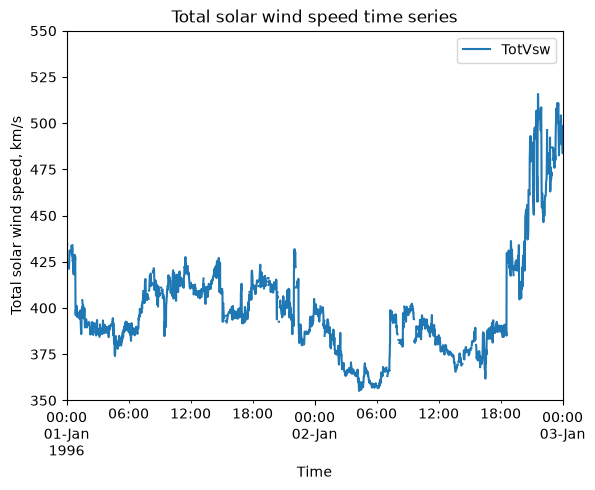

In [22]:
timestart = "1996-01-01 00:00"
timeend = "1996-01-03 00:00"
xlimS = timestart #"1996-01-01 00:00"
xlimE = timeend #"1996-01-01 04:00"
ylimS = 350
ylimE = 550

testingSeries = dataTimeSerieses[0].truncate(timestart, timeend)

# PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [200,800])
PlotVsw(testingSeries, Columns=["TotVsw"], XLim =[xlimS, xlimE], YLim = [ylimS,ylimE])

Alpha = 0.3
RelativeThreshold = 0.05

start = []
end = []
# start = timestart
# end = timestart
# en
# dataTimeSerieses[0] -> testingSeries below
for i in range(len(testingSeries.to_dataframe()["TotVsw"])):
    if str(testingSeries.to_dataframe()["TotVsw"].values[i]) == "nan": # ignore nan values
        print("Nan")

    else:
        # #Edgecase
        # if i <100:
        #     print("This is the start.") # basic way to avoid edge, needs fixed
        # if i > (len(testingSeries.to_dataframe()["TotVsw"])-100): # near end, just stop without checking steadiness
        #     print("This is the end.")
        #     break

        # else:
        #Main case
        basevalue = testingSeries.to_dataframe()["TotVsw"].values[i] # set base value
        thresMax = basevalue + (basevalue*RelativeThreshold) # add threshold
        thresMin = basevalue - (basevalue*RelativeThreshold) # minus threshold
        print(basevalue)
        print("Base value = " + str(basevalue) + ", ThresMax = " + str(thresMax)+ ", ThresMin = " + str(thresMin)) # print chosen values

        for j in range(1,i): # for values before this one in the timeseries
            if i-j <= 0: # edge case for beginning?
                print("Start of values")
                start.append(testingSeries.to_dataframe()["TotVsw"].index[0]) # set the end time to end timestamp
                break
            else:
                if testingSeries.to_dataframe()["TotVsw"].values[i-j] >= thresMax or testingSeries.to_dataframe()["TotVsw"].values[i-j] <= thresMin: #if the value is outside the threshold range
                    print("Closest neighbour = " + str(j) + " away.") # choose it as the closest neighbour
                    start.append(testingSeries.to_dataframe()["TotVsw"].index[i-j+1]) # set the start time to the timestamp after this one
                    break # stop looking for a closest neighbour
                else:
                    print("Still looking.") # print that you're still looking

        for k in range(1,i): # for values after this one in the timeseries
            if i+k >= len(testingSeries.to_dataframe()["TotVsw"]):
                print("End of values")
                end.append(testingSeries.to_dataframe()["TotVsw"].index[-1]) # set the end time to end timestamp
                break
            else:
                if testingSeries.to_dataframe()["TotVsw"].values[i+k] >= thresMax or testingSeries.to_dataframe()["TotVsw"].values[i+k] <= thresMin: #if the value is outside the threshold range
                    print("Closest neighbour = " + str(k) + " away.") # choose it as the closest neighbour
                    end.append(testingSeries.to_dataframe()["TotVsw"].index[i+k-1]) # set the end time to  the timestamp before this one
                    break # stop looking for a closest neighbour
                else:
                    print("Still looking.") # print that you're still looking

# plt.axvspan(start[-1], end[-1], color = colour1, alpha = Alpha)

print(len(start))
print(len(end))
# plt.hlines(thresMin, xmin = timestart, xmax = timeend, color=colour1)
# plt.hlines(thresMax - AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)


#General plot settings
plt.title("Total solar wind speed time series")
plt.xlabel("Time")
plt.ylabel("Total solar wind speed, km/s")
# print("Caption: Time series of solar wind speed with highlighted times that the values stay within the first ("+ str(FirstBaseValue-AbsoluteThreshold) + "-" + str(FirstBaseValue+AbsoluteThreshold)+"km/s, "+ colour1+")\n and second ("+ str(SecondBaseValue-AbsoluteThreshold) + "-" + str(SecondBaseValue+AbsoluteThreshold)+"km/s, "+ colour2+") threshold. Highlighted sections are coloured coded to show each threshold.")


In [23]:
print(start)
print(end)

[Timestamp('1996-01-01 00:35:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('1996-01-01 00:51:00'), Timestamp('19

In [24]:
print(testingSeries.to_dataframe()["TotVsw"].index)

DatetimeIndex(['1996-01-01 00:00:00', '1996-01-01 00:01:00',
               '1996-01-01 00:02:00', '1996-01-01 00:03:00',
               '1996-01-01 00:04:00', '1996-01-01 00:05:00',
               '1996-01-01 00:06:00', '1996-01-01 00:07:00',
               '1996-01-01 00:08:00', '1996-01-01 00:09:00',
               ...
               '1996-01-02 23:51:00', '1996-01-02 23:52:00',
               '1996-01-02 23:53:00', '1996-01-02 23:54:00',
               '1996-01-02 23:55:00', '1996-01-02 23:56:00',
               '1996-01-02 23:57:00', '1996-01-02 23:58:00',
               '1996-01-02 23:59:00', '1996-01-03 00:00:00'],
              dtype='datetime64[us]', name='DateTime', length=2881, freq=None)


File not saved
2663
2494
0
0
too short
2663
2494
1
10
too short
2663
2494
2
20
too short
2663
2494
3
30
too short
2663
2494
4
40
too short
2663
2494
5
50
too short
2663
2494
6
60
too short
2663
2494
7
70
too short
2663
2494
8
80
too short
2663
2494
9
90
too short
2663
2494
10
100
too short
2663
2494
11
110
too short
2663
2494
12
120
too short
2663
2494
13
130
too short
2663
2494
14
140
too short
2663
2494
15
150
too short
2663
2494
16
160
too short
2663
2494
17
170
too short
2663
2494
18
180
too short
2663
2494
19
190
too short
2663
2494
20
200
too short
2663
2494
21
210
too short
2663
2494
22
220
too short
2663
2494
23
230
too short
2663
2494
24
240
2663
2494
25
250
2663
2494
26
260
2663
2494
27
270
2663
2494
28
280
2663
2494
29
290
2663
2494
30
300
2663
2494
31
310
2663
2494
32
320
2663
2494
33
330
2663
2494
34
340
2663
2494
35
350
2663
2494
36
360
2663
2494
37
370
2663
2494
38
380
2663
2494
39
390
2663
2494
40
400
2663
2494
41
410
2663
2494
42
420
2663
2494
43
430
2663
2494
44
440
2

IndexError: list index out of range

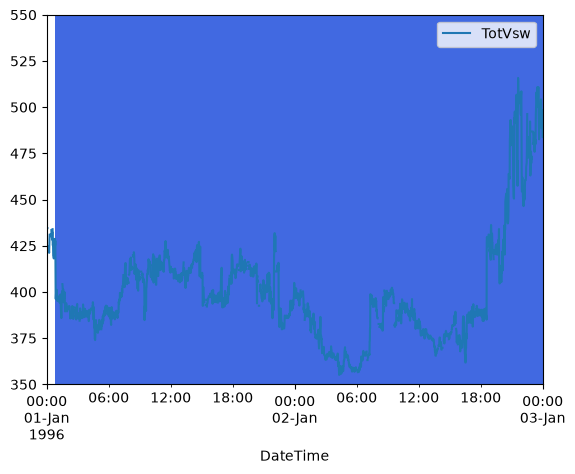

In [34]:
timestart = "1996-01-01 00:00"
timeend = "1996-01-03 00:00"
xlimS = timestart #"1996-01-01 00:00"
xlimE = timeend #"1996-01-01 04:00"
ylimS = 350
ylimE = 550

testingSeries = dataTimeSerieses[0].truncate(timestart, timeend)

# PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [200,800])
PlotVsw(testingSeries, Columns=["TotVsw"], XLim =[xlimS, xlimE], YLim = [ylimS,ylimE])

Alpha = 0.1
RelativeThreshold = 0.05

from datetime import datetime, timedelta

for a in range(len(start)):
    print(len(start))
    print(len(end))
    print(a)
    print(a*10)

    if end[a] - start[a] < timedelta(minutes=60):
        print("too short")
    elif a <= len(start):
        plt.axvspan(start[a], end[a], color = colour1, alpha = Alpha)
    else:
        break

# plt.hlines(thresMin, xmin = timestart, xmax = timeend, color=colour1)
# plt.hlines(thresMax - AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)


#General plot settings
plt.title("Total solar wind speed time series")
plt.xlabel("Time")
plt.ylabel("Total solar wind speed, km/s")
# print("Caption: Time series of solar wind speed with highlighted times that the values stay within the first ("+ str(FirstBaseValue-AbsoluteThreshold) + "-" + str(FirstBaseValue+AbsoluteThreshold)+"km/s, "+ colour1+")\n and second ("+ str(SecondBaseValue-AbsoluteThreshold) + "-" + str(SecondBaseValue+AbsoluteThreshold)+"km/s, "+ colour2+") threshold. Highlighted sections are coloured coded to show each threshold.")

# New version saved